# UK Power Prices and European Gas (TTF)
I heard from somewhere that the UK Power price is becoming less dependent on Gas power with the growing of solar and wind. So this project is made to prove if that claim is true or not. 
- Data: Elexon, Yahoo Finance 
- Made by: Ittikorn Chanahaworrachai 28th October 2026

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
import sys

!{sys.executable} -m pip install elexonpy


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip3.12 install --upgrade pip


## UK wholesale electricity price (Elexon)

Uses Elexon's **Market Index Data (MID)**, the half-hourly wholesale spot price (£/MWh) from the APX/EPEX exchange,
available from 2016. The API only allows **7 days per request**, so the date range is split into weekly chunks,
fetched in parallel and cached to CSV so later runs don't re-download.

In [3]:
import os
import time
from concurrent.futures import ThreadPoolExecutor

import requests

ELEXON_MID_URL = "https://data.elexon.co.uk/bmrs/api/v1/balancing/pricing/market-index"
START, END = "2016-10-01", "2026-10-28"
CACHE_FILE = "uk_power_mid.csv"


def fetch_mid_week(start):
    """Fetch one 7-day chunk of half-hourly MID prices (API limit is 7 days per call)."""
    end = start + pd.Timedelta(days=6, hours=23, minutes=30)
    params = {
        "from": start.strftime("%Y-%m-%dT%H:%MZ"),
        "to": end.strftime("%Y-%m-%dT%H:%MZ"),
        "dataProviders": "APXMIDP",
        "format": "json",
    }
    for attempt in range(3):
        try:
            r = requests.get(ELEXON_MID_URL, params=params, timeout=30)
            r.raise_for_status()
            return pd.DataFrame(r.json()["data"])
        except requests.RequestException:
            time.sleep(2 ** attempt)
    print(f"Failed to fetch week starting {start.date()}")
    return pd.DataFrame()


# Load the cache, then fetch only the weeks after its last day (the whole range if there's no cache)
if os.path.exists(CACHE_FILE):
    mid = pd.read_csv(CACHE_FILE)
    week_starts = pd.date_range(mid["settlementDate"].max(), END, freq="7D")
else:
    mid = pd.DataFrame()
    week_starts = pd.date_range(START, END, freq="7D")
if len(week_starts):
    with ThreadPoolExecutor(max_workers=8) as ex:
        mid = pd.concat([mid, *ex.map(fetch_mid_week, week_starts)], ignore_index=True)
    # keep="last" so a day that was only partly published at the last fetch is replaced in full
    mid = mid.drop_duplicates(["settlementDate", "settlementPeriod"], keep="last")
    mid.to_csv(CACHE_FILE, index=False)

# Zero-volume periods carry a placeholder price of 0, so drop them before averaging
mid = mid[mid["volume"] > 0]
mid["date"] = pd.to_datetime(mid["settlementDate"])

# Aggregate the 48 half-hourly prices into a daily average (£/MWh)
uk_power_daily = mid.groupby("date")["price"].mean().rename("UK Power")

print(f"{len(mid):,} half-hourly rows -> {len(uk_power_daily):,} days")
print(uk_power_daily.resample("YE").mean().round(1))

173,681 half-hourly rows -> 3,644 days
date
2016-12-31     50.2
2017-12-31     44.7
2018-12-31     56.9
2019-12-31     41.8
2020-12-31     33.5
2021-12-31    114.7
2022-12-31    198.2
2023-12-31     93.6
2024-12-31     71.4
2025-12-31     79.9
2026-12-31    106.5
Freq: YE-DEC, Name: UK Power, dtype: float64


## Merge with oil and gas

UK power prices are set mostly by **European gas**, so add Dutch TTF gas (`TTF=F`, €/MWh, history starts in late 2017)
alongside Brent and US Henry Hub gas (`NG=F`).

Power trades every day but futures only trade on weekdays, so an inner join keeps trading days only.
That's why the earlier single-day attempt (2026-10-10, a Saturday) returned 0 rows.

/var/folders/m5/pl7f3qbs4wz97g9ld9_84ysw0000gn/T/ipykernel_32936/1483115706.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  energy_px = yf.download(list(energy_tickers.values()), start=START, end=END, progress=False)["Close"]
/opt/anaconda3/lib/python3.12/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


Aligned trading days: 2243 (2017-10-23 to 2026-10-27)


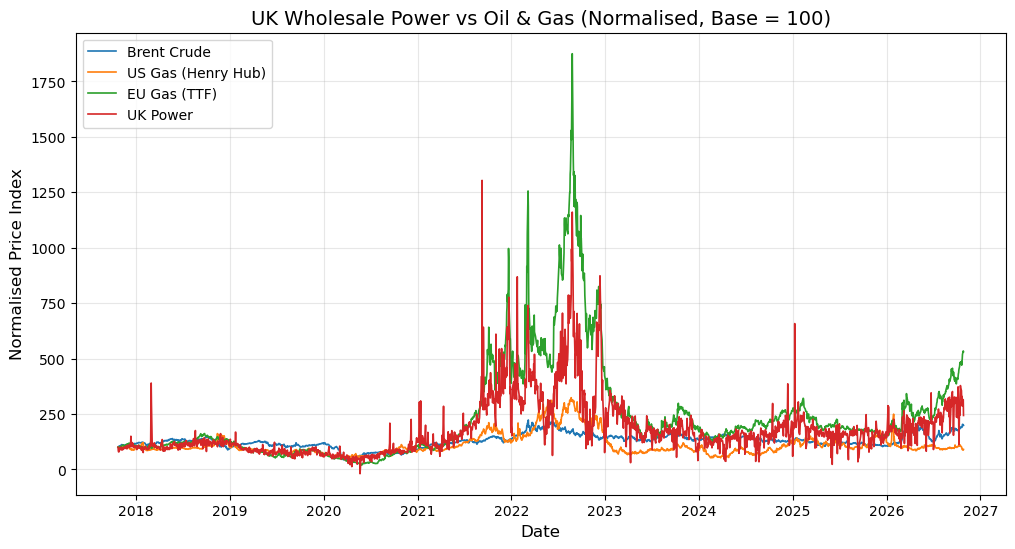

In [4]:
energy_tickers = {"Brent Crude": "BZ=F", "US Gas (Henry Hub)": "NG=F", "EU Gas (TTF)": "TTF=F"}

energy_px = yf.download(list(energy_tickers.values()), start=START, end=END, progress=False)["Close"]
energy_px = energy_px.rename(columns={v: k for k, v in energy_tickers.items()})

master = energy_px.join(uk_power_daily, how="inner").dropna()
print(f"Aligned trading days: {len(master)} ({master.index[0].date()} to {master.index[-1].date()})")

# Normalised trends (base = 100 on first common day)
normalized_master = master / master.iloc[0] * 100

plt.figure(figsize=(12, 6))
for column in normalized_master.columns:
    plt.plot(normalized_master.index, normalized_master[column], label=column, linewidth=1.2)
plt.title("UK Wholesale Power vs Oil & Gas (Normalised, Base = 100)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Normalised Price Index", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

## Past year: UK power vs EU & US gas (normalised)

The three series are in different units (£/MWh, €/MWh, $/MMBtu), so they are normalised to compare shape:
- **Rebased to 100** shows the percentage move since the start of the window.
- **Z-score** puts each series in its own standard deviations, so a volatile series doesn't dominate the chart.

A 5-day rolling mean removes the daily wind/weekend noise in UK power.

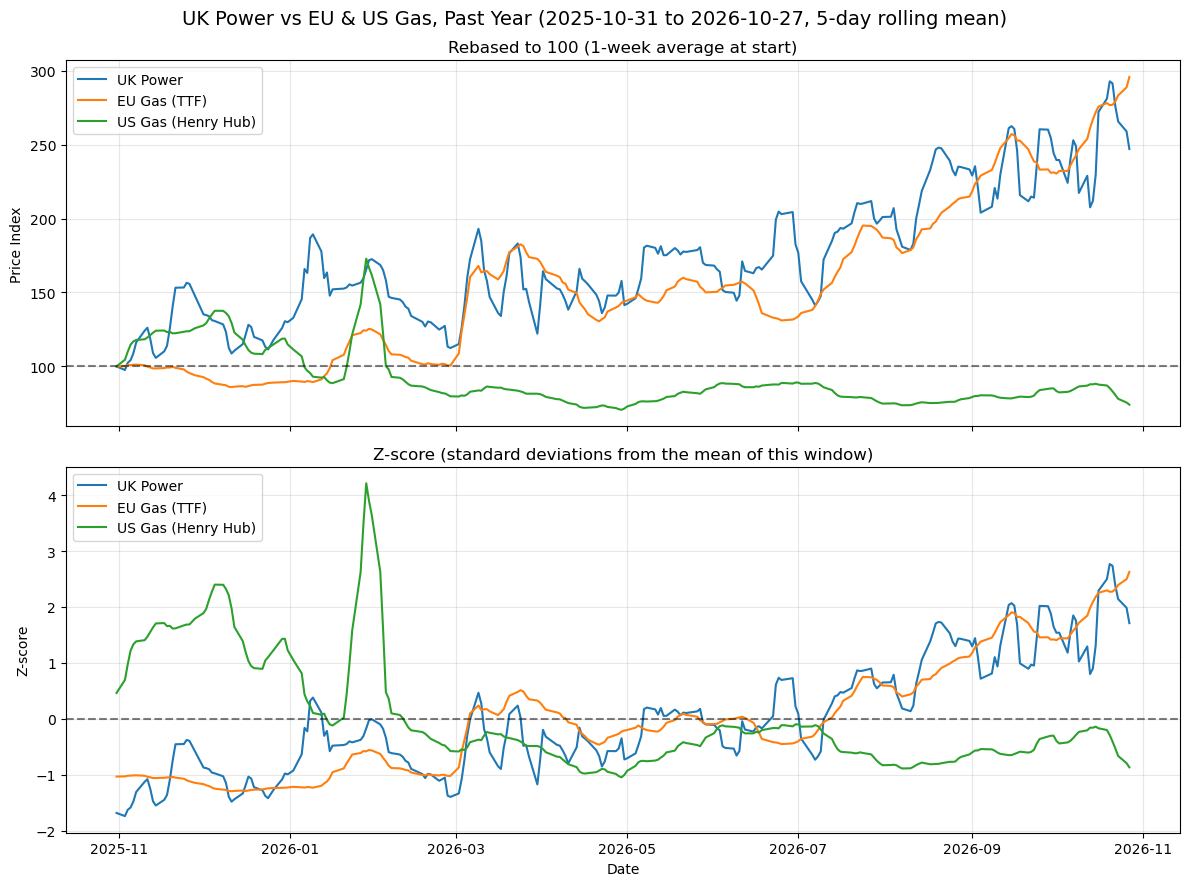

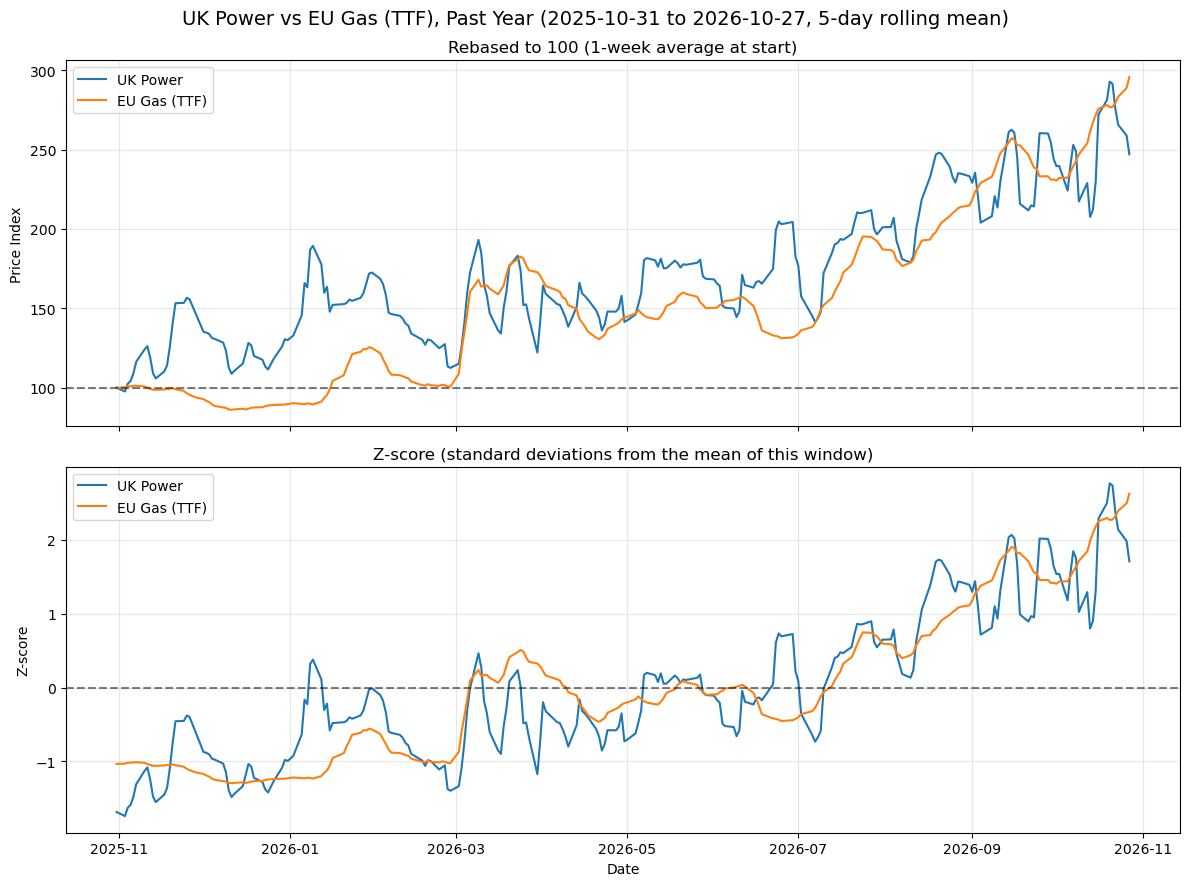

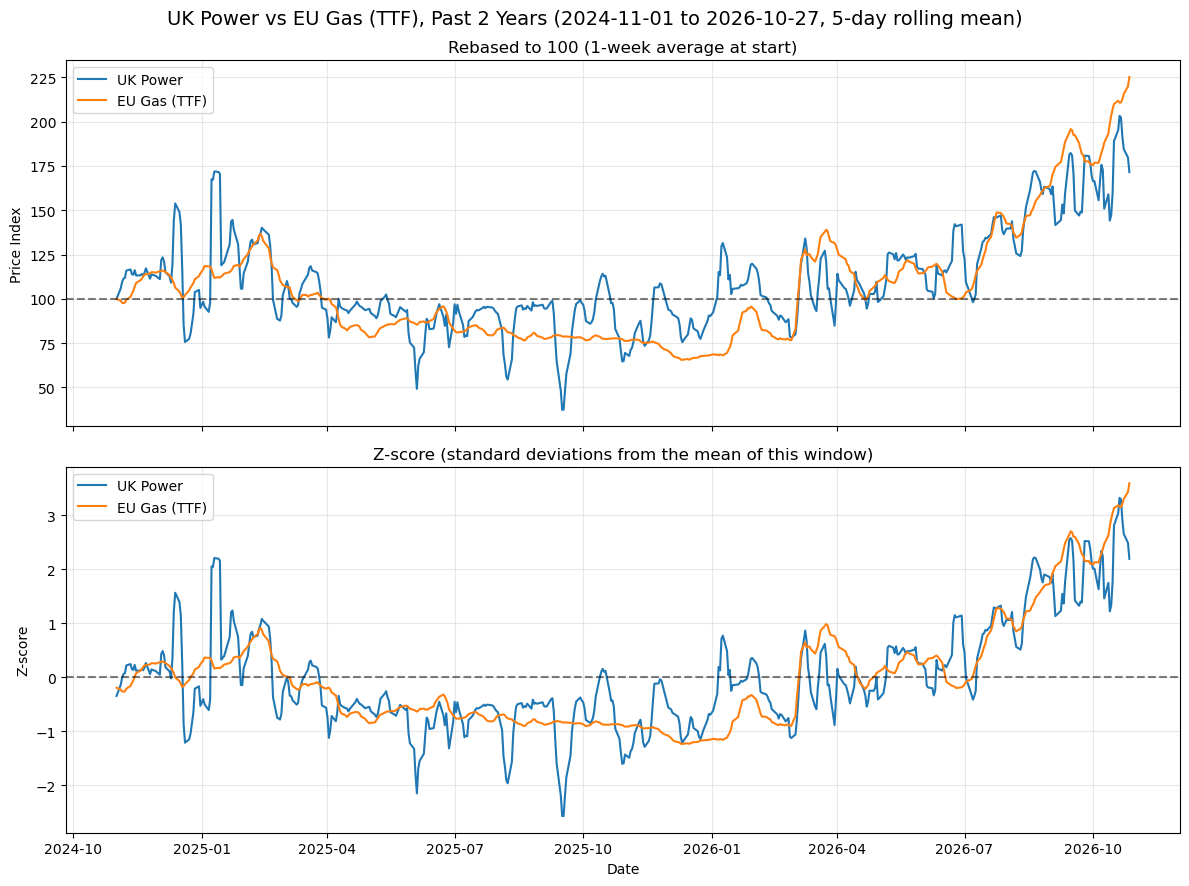

In [5]:
import matplotlib.pyplot as plt


def plot_energy_comparison(df, columns_to_plot, title_suffix, years=1, start=None):
  # Filter data from `start` if given, otherwise the last `years` years
  if start is None:
    start = df.index[-1] - pd.DateOffset(years=years)
  window = df.loc[start:, columns_to_plot]

  # Smooth with a 5-trading-day rolling mean to remove noise
  smoothed = window.rolling(5).mean().dropna()

  # Transform data: Rebase to 100 and calculate Z-scores
  rebased = smoothed / smoothed.iloc[0] * 100
  zscored = (smoothed - smoothed.mean()) / smoothed.std()

  # Setup the 2-panel figure layout
  fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

  for col in columns_to_plot:
    ax1.plot(rebased.index, rebased[col], label=col, linewidth=1.5)
    ax2.plot(zscored.index, zscored[col], label=col, linewidth=1.5)

  # Formatting Panel 1 (Rebased)
  ax1.axhline(100, color="black", linestyle="--", alpha=0.5)
  ax1.set_title("Rebased to 100 (1-week average at start)", fontsize=12)
  ax1.set_ylabel("Price Index")

  # Formatting Panel 2 (Z-score)
  ax2.axhline(0, color="black", linestyle="--", alpha=0.5)
  ax2.set_title(
      "Z-score (standard deviations from the mean of this window)",
      fontsize=12,
  )
  ax2.set_ylabel("Z-score")
  ax2.set_xlabel("Date")

  for ax in (ax1, ax2):
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)

  fig.suptitle(
      f"{title_suffix} ({smoothed.index[0].date()} to"
      f" {smoothed.index[-1].date()}, 5-day rolling mean)",
      fontsize=14,
  )
  plt.tight_layout()
  plt.show()



plot_energy_comparison(
    master,
    ["UK Power", "EU Gas (TTF)", "US Gas (Henry Hub)"],
    "UK Power vs EU & US Gas, Past Year",
)


plot_energy_comparison(
    master, ["UK Power", "EU Gas (TTF)"], "UK Power vs EU Gas (TTF), Past Year"
)


plot_energy_comparison(
    master,
    ["UK Power", "EU Gas (TTF)"],
    "UK Power vs EU Gas (TTF), Past 2 Years",
    years=2,
)

The US gas or Henry Hub is on it's own path as shown on the green line. So I excluded it to focus this project to only EU gas and UK power.

UK power and EU gas (TTF) both rose into winter 2024–25, fell through mid-2025 and bottomed around January 2026.
Both have climbed since the US–Israeli strikes on Iran began on 28 February 2026: TTF rose more than 70% in March as Qatar halted LNG output and tanker traffic through the Strait of Hormuz nearly stopped.

Since August 2026, TTF has risen more in percentage terms than UK power (about +64% vs +37% to late October). This does **not** mean UK power is becoming less linked to gas.
Only part of the power price moves with gas: about £30/MWh (mostly carbon cost) stays fixed, so power always rises by a smaller *percentage* than gas.
A gas-only model fitted before August predicted UK power would average about £139/MWh from August to late October; it actually averaged £143 (see the residual test below).

## Zoom: August 2026 onwards

Since August, TTF has risen more in percentage terms than UK power (top panel below). 

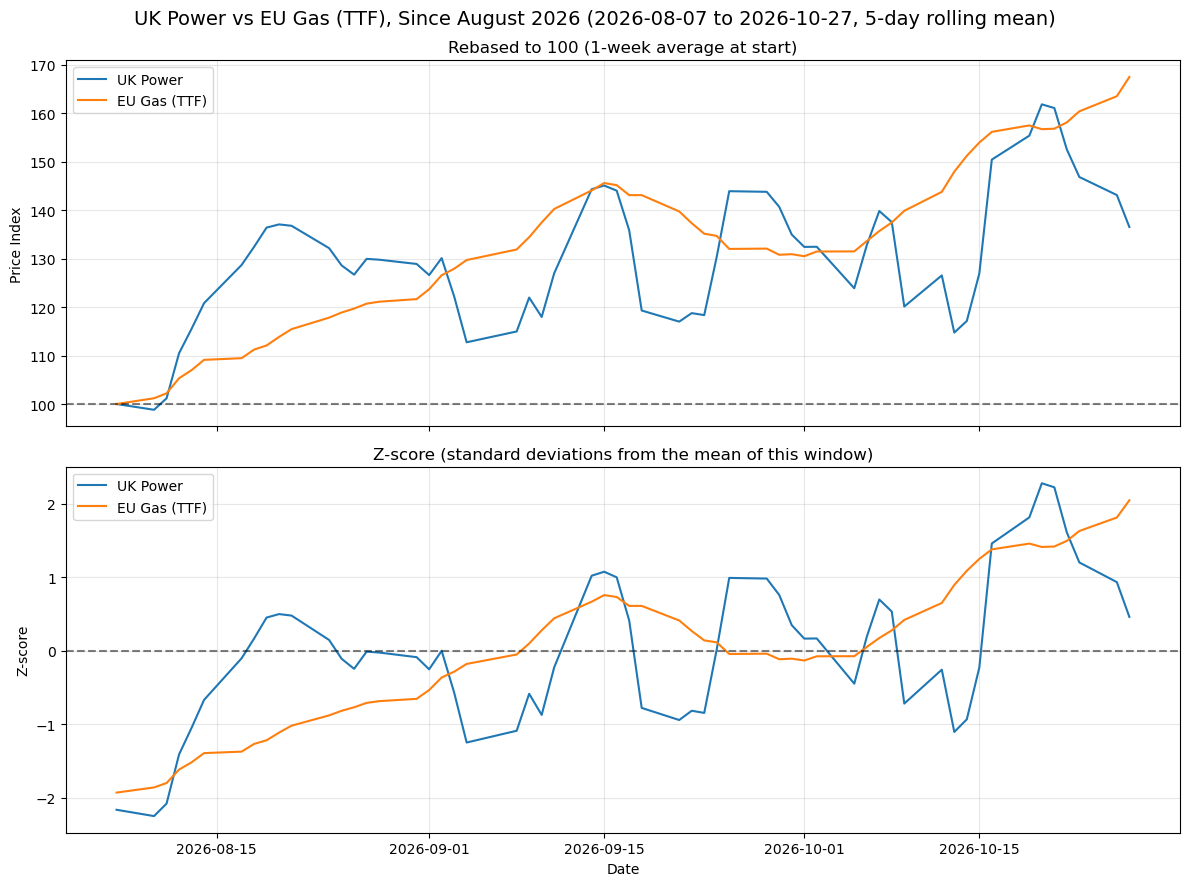

In [6]:
plot_energy_comparison(
    master,
    ["UK Power", "EU Gas (TTF)"],
    "UK Power vs EU Gas (TTF), Since August 2026",
    start="2026-08-01",
)

## Correlation: UK power vs EU gas (TTF)

TTF is converted from €/MWh to £/MWh with EURGBP so both prices are in the same units.
Correlation is measured on price levels and on log returns at three frequencies. Daily changes are dominated by weather,
so the gas link shows up more clearly at longer horizons.

/var/folders/m5/pl7f3qbs4wz97g9ld9_84ysw0000gn/T/ipykernel_32936/2942266151.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  eurgbp = yf.download("EURGBP=X", start=START, end=END, progress=False)["Close"].squeeze()
/opt/anaconda3/lib/python3.12/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/internals/blocks.py:347: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


--- Correlation of UK Power with EU Gas (TTF) ---
                 Full history (2017-2026)  Last 2 years
Price levels                        0.868         0.664
Daily returns                       0.063         0.022
Weekly returns                      0.335         0.195
Monthly returns                     0.681         0.634


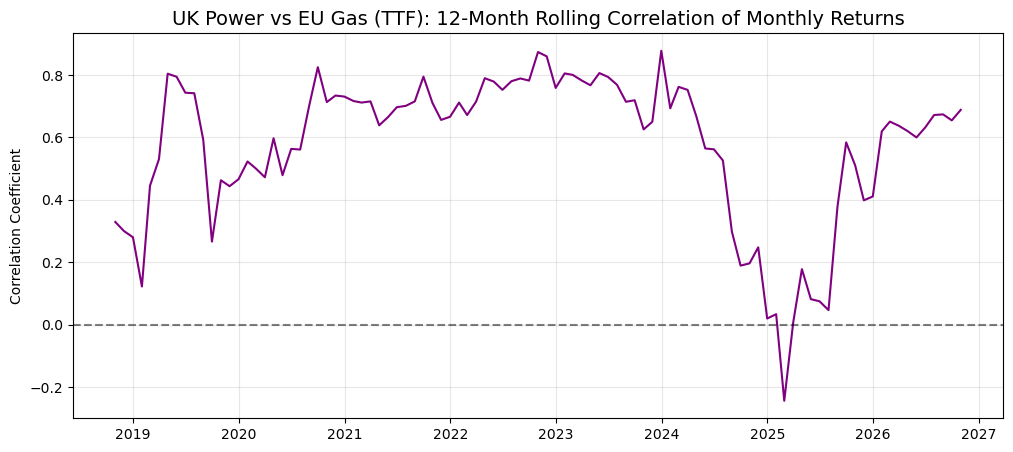


Correlation between rolling correlation and gas volatility: 0.82


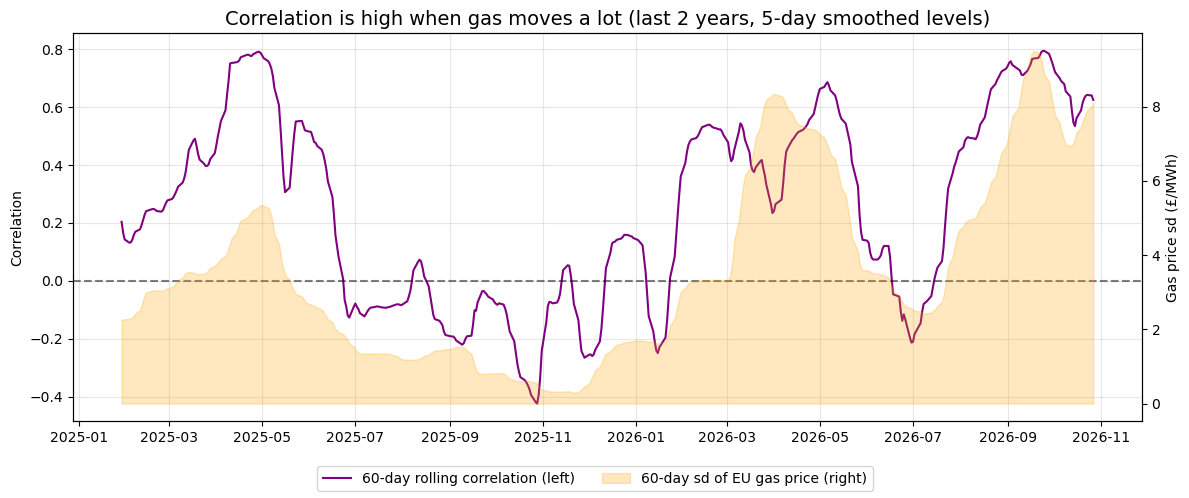

In [7]:
# TTF is in €/MWh; convert to £/MWh so both prices are in the same units
eurgbp = yf.download("EURGBP=X", start=START, end=END, progress=False)["Close"].squeeze()
uk_ttf = master[["UK Power"]].copy()
uk_ttf["EU Gas (£/MWh)"] = master["EU Gas (TTF)"] * eurgbp.reindex(master.index).ffill()
uk_ttf = uk_ttf.dropna()
last_2y = uk_ttf.loc[uk_ttf.index[-1] - pd.DateOffset(years=2) :]


def power_gas_corr(df):
    """Correlation of UK power with EU gas at daily, weekly and monthly frequency."""
    def corr(x):
        return x["UK Power"].corr(x["EU Gas (£/MWh)"])

    return pd.Series({
        "Price levels": corr(df),
        "Daily returns": corr(np.log(df).diff()),
        "Weekly returns": corr(np.log(df.resample("W-FRI").mean()).diff()),
        "Monthly returns": corr(np.log(df.resample("ME").mean()).diff()),
    })


corr_table = pd.DataFrame({
    f"Full history ({uk_ttf.index[0].year}-{uk_ttf.index[-1].year})": power_gas_corr(uk_ttf),
    "Last 2 years": power_gas_corr(last_2y),
})
print("--- Correlation of UK Power with EU Gas (TTF) ---")
print(corr_table.round(3))

# Rolling 12-month correlation of monthly returns (full history)
monthly_ret = np.log(uk_ttf.resample("ME").mean()).diff().dropna()
plt.figure(figsize=(12, 5))
plt.plot(monthly_ret["UK Power"].rolling(12).corr(monthly_ret["EU Gas (£/MWh)"]), color="purple", linewidth=1.5)
plt.axhline(0, color="black", linestyle="--", alpha=0.5)
plt.title("UK Power vs EU Gas (TTF): 12-Month Rolling Correlation of Monthly Returns", fontsize=14)
plt.ylabel("Correlation Coefficient")
plt.grid(True, alpha=0.3)
plt.show()

# Last 2 years: does correlation rise when gas moves a lot?
smoothed_2y = last_2y.rolling(5).mean()
rolling_corr = smoothed_2y["UK Power"].rolling(60).corr(smoothed_2y["EU Gas (£/MWh)"])
gas_volatility = smoothed_2y["EU Gas (£/MWh)"].rolling(60).std()
print(f"\nCorrelation between rolling correlation and gas volatility: {rolling_corr.corr(gas_volatility):.2f}")

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(rolling_corr.index, rolling_corr, color="purple", linewidth=1.5, label="60-day rolling correlation (left)")
ax1.axhline(0, color="black", linestyle="--", alpha=0.5)
ax1.set_ylabel("Correlation")
ax2 = ax1.twinx()
ax2.fill_between(gas_volatility.index, gas_volatility, color="orange", alpha=0.25, label="60-day sd of EU gas price (right)")
ax2.set_ylabel("Gas price sd (£/MWh)")
fig.legend(loc="lower center", ncol=2)
ax1.set_title("Correlation is high when gas moves a lot (last 2 years, 5-day smoothed levels)", fontsize=14)
ax1.grid(True, alpha=0.3)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

### Why correlation is high from March 2026

- **Correlation rises and falls with how much gas is moving.** Over the last 2 years, the 60-day correlation and the 60-day volatility of gas (two lines above) correlate at 0.82.
- **UK power has two parts:** a gas-driven part and a weather part (wind, solar, demand) that is noisy day to day.
  When gas is flat, as in Jun–Nov 2025 (60-day sd below £2/MWh), only the weather noise is visible and correlation falls to about zero.
  When gas moves a lot, as after the Iran strikes in March 2026 and again from August, the gas signal outweighs the noise and correlation rises to 0.6–0.8.
- **It wasn't continuous.** March–October 2026 (Since Iran war) as a whole correlates at 0.81, but correlation dipped below zero in June–July when gas briefly stopped moving.

This shows that it is possible that when the EU gas is volatile, the correlation is high. 
So a high or low correlation here says more about **how much gas is moving** than about **how dependent** UK power is on gas.
The regression slope below is the better measure of dependence.


## Regression: UK power on EU gas

Three regressions over the full history (2017–2026):
- **Levels:** power (£/MWh) = a + b × gas (£/MWh). The slope b is how many £ power moves per £1 move in gas.
- **Weekly and monthly log returns:** Δln(power) = α + β × Δln(gas). β is the elasticity: a 1% move in gas gives a β% move in power.

The **Durbin-Watson** statistic checks whether residuals are autocorrelated: about 2 is fine; well below 2 means the residuals carry a trend the model misses.

--- UK Power on EU Gas (TTF), 2017-10-23 to 2026-10-27 ---
                     Slope  Intercept     R²  p-value  Durbin-Watson     Obs
Levels (£/MWh)       1.663     29.588  0.753      0.0          0.786  2243.0
Weekly log returns   0.773     -0.000  0.113      0.0          2.566   470.0
Monthly log returns  0.774      0.001  0.463      0.0          2.440   108.0


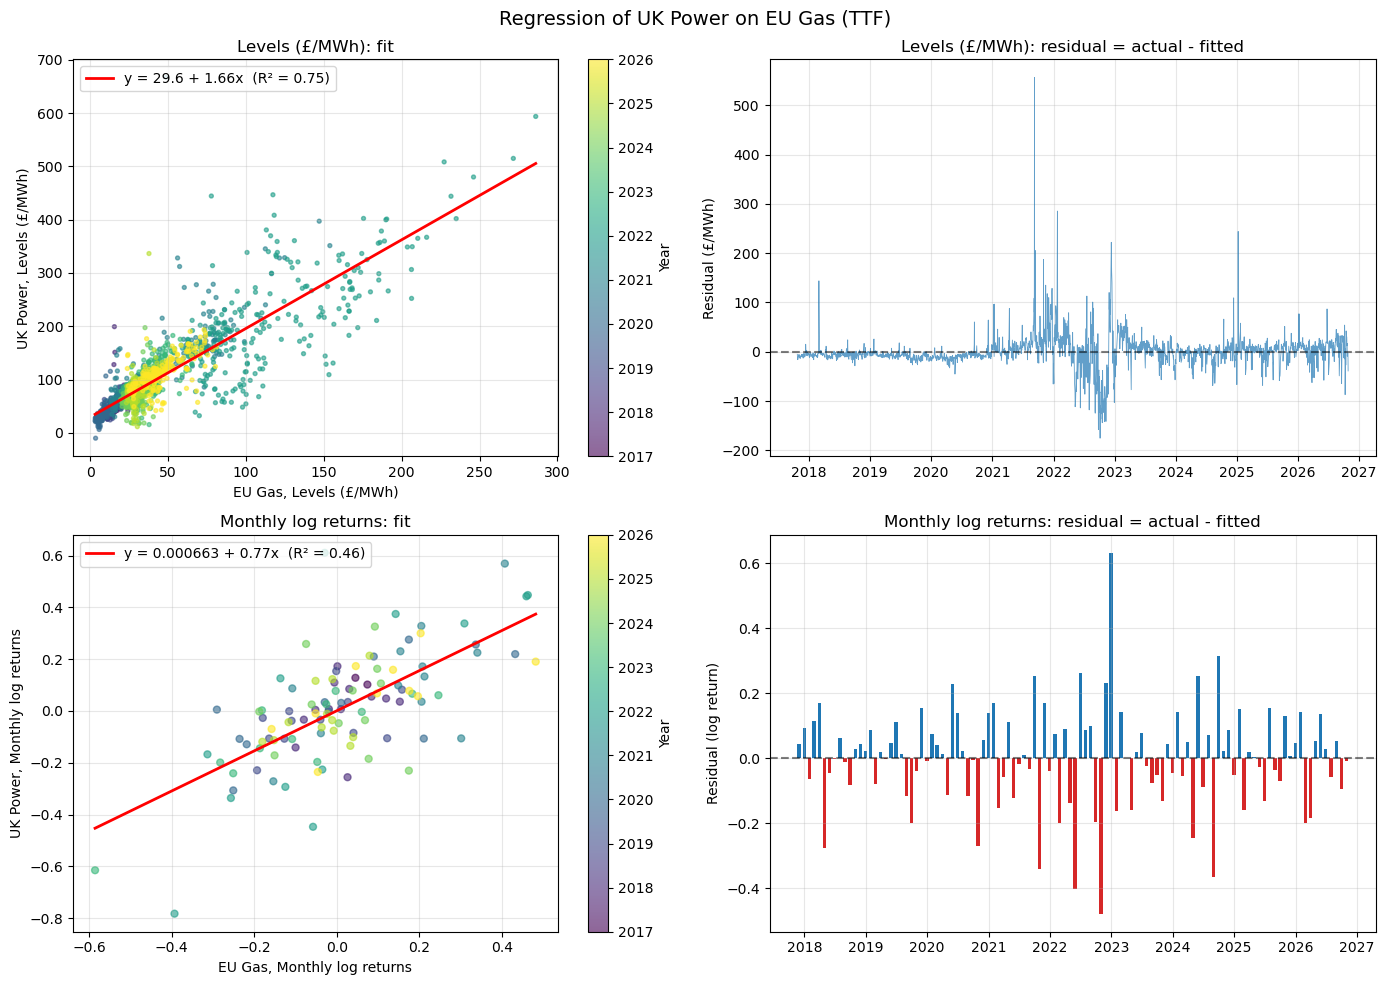

In [8]:
from scipy import stats


def ols(x, y):
    """OLS of y on x. Durbin-Watson near 2 means no autocorrelation in the residuals."""
    fit = stats.linregress(x, y)
    resid = y - (fit.intercept + fit.slope * x)
    dw = (resid.diff() ** 2).sum() / (resid ** 2).sum()
    return fit, resid, dw


datasets = {
    "Levels (£/MWh)": uk_ttf,
    "Weekly log returns": np.log(uk_ttf.resample("W-FRI").mean()).diff().dropna(),
    "Monthly log returns": np.log(uk_ttf.resample("ME").mean()).diff().dropna(),
}
summary, fits = {}, {}
for name, data in datasets.items():
    fit, resid, dw = ols(data["EU Gas (£/MWh)"], data["UK Power"])
    fits[name] = (data, fit, resid)
    summary[name] = {
        "Slope": fit.slope, "Intercept": fit.intercept, "R²": fit.rvalue**2,
        "p-value": fit.pvalue, "Durbin-Watson": dw, "Obs": len(data),
    }
print(f"--- UK Power on EU Gas (TTF), {uk_ttf.index[0].date()} to {uk_ttf.index[-1].date()} ---")
print(pd.DataFrame(summary).T.round(3).to_string())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row, name in enumerate(["Levels (£/MWh)", "Monthly log returns"]):
    data, fit, resid = fits[name]
    x, y = data["EU Gas (£/MWh)"], data["UK Power"]
    ax_fit, ax_res = axes[row]

    # Left: scatter with fitted line (coloured by year to show regime changes)
    points = ax_fit.scatter(x, y, c=data.index.year, cmap="viridis", s=8 if row == 0 else 25, alpha=0.6)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax_fit.plot(x_line, fit.intercept + fit.slope * x_line, color="red", linewidth=2,
                label=f"y = {fit.intercept:.3g} + {fit.slope:.2f}x  (R² = {fit.rvalue**2:.2f})")
    ax_fit.set_xlabel(f"EU Gas, {name}")
    ax_fit.set_ylabel(f"UK Power, {name}")
    ax_fit.set_title(f"{name}: fit", fontsize=12)
    ax_fit.legend(loc="upper left")
    fig.colorbar(points, ax=ax_fit, label="Year")

    # Right: residuals over time
    if row == 0:
        ax_res.plot(resid.index, resid, linewidth=0.6, alpha=0.7)
        ax_res.set_ylabel("Residual (£/MWh)")
    else:
        ax_res.bar(resid.index, resid, width=20, color=np.where(resid > 0, "tab:blue", "tab:red"))
        ax_res.set_ylabel("Residual (log return)")
    ax_res.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax_res.set_title(f"{name}: residual = actual - fitted", fontsize=12)
    for ax in (ax_fit, ax_res):
        ax.grid(True, alpha=0.3)

fig.suptitle("Regression of UK Power on EU Gas (TTF)", fontsize=14)
plt.tight_layout()
plt.show()

### What the regressions show

- **Levels: power ≈ £30 + 1.66 × gas (R² 0.75).** This has a physical meaning: a gas power station (CCGT) at about 55–60% efficiency burns about 1.7 MWh of gas per MWh of electricity, which matches the slope. The £30 intercept is mostly the carbon cost (see below).
- **Don't trust the levels R² on its own.** Durbin-Watson is 0.79, so residuals are strongly autocorrelated, and the residual plot shows them swelling in 2021–23 when prices were high (heteroskedasticity). Two trending series make R² look better than it is. The proper test is cointegration (Engle-Granger, `statsmodels.tsa.stattools.coint`).
- **Monthly returns are the cleaner model: β = 0.77, R² 0.46.** A 10% monthly rise in gas goes with about a 7.7% rise in UK power. Durbin-Watson is 2.4 and the residual bars show no clear pattern, so the remaining 54% is mostly weather and demand.
- **β < 1 is explained by the fixed intercept.** Since about £30 of the power price doesn't move with gas, a 10% rise in gas raises power by less than 10%. This is also why power rose less than gas since August.
- **Weekly returns: R² only 0.11.** Week to week, weather swamps the gas link.

### Carbon Price
This affects power prices as well, hence it could act as a noise when assess gas and power relationship
A UK gas plant's cost to make 1 MWh of electricity is approximately:

**gas price × 1.7 + 0.35 tCO₂ × (UK ETS price + £18/t Carbon Price Support)**

At a UK ETS price of £49–62/t, the carbon term is about £23–28/MWh, which is most of the £30 intercept. Adding carbon to the regression would:
1. **Explain the intercept** instead of leaving it as an unexplained constant.
2. **Stop carbon moves being misread as decoupling.** UK carbon rose to about £62/t in late September 2026 on talk of linking with the EU ETS. A higher carbon price pushes power up with no change in gas, which a gas-only model shows as a positive residual. A fall in carbon would make power look cheaper than gas implies, which is fake decoupling.
3. **Reduce omitted-variable bias.** If carbon and gas prices move together, the gas-only slope partly absorbs the carbon effect.

UK ETS prices aren't on yfinance; ICE UKA futures or the UK government's published auction results are the usual sources.

## Residual test: is UK power decoupling from gas?

A gas-only model is fitted on Oct 2024 to Jul 2026: **UK Power = a + b × EU Gas**, with TTF converted to £/MWh.
The model is then used to predict August 2026 onwards, data it never saw (shaded).

- If UK power were becoming **less dependent on gas**, the model would over-predict after August and the residual
  (actual − predicted) would sit persistently **below zero**, outside the normal ±1 sd band.
- A residual hovering around zero means the old gas relationship still explains power prices.

Fit (before 2026-08-01): UK Power = 32.5 + 1.70 x EU Gas  [£/MWh]
Mean residual before 2026-08-01: -0.0 £/MWh (sd 22.8)
Mean residual from   2026-08-01: +4.0 £/MWh

Monthly mean residual since August (£/MWh):
Date
2026-08-31    12.1
2026-09-30     0.4
2026-10-31    -0.9
Freq: ME

Aug -> Oct: gas +64%, model-predicted power +45%, actual power +37%


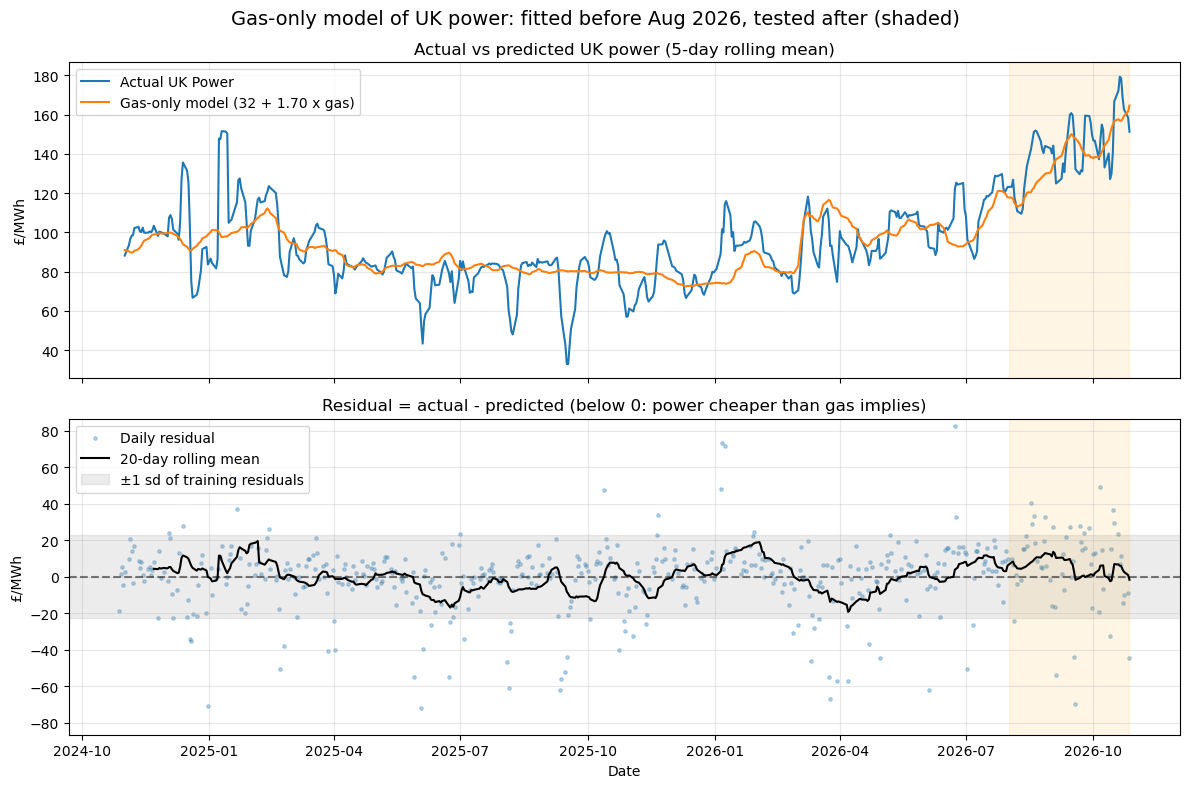

In [9]:
pg = last_2y.copy()

# Fit on the 21 months before August 2026, then test on August onwards (out of sample)
SPLIT = "2026-08-01"
train = pg.index < SPLIT
slope, intercept = np.polyfit(pg.loc[train, "EU Gas (£/MWh)"], pg.loc[train, "UK Power"], 1)
pg["Predicted"] = intercept + slope * pg["EU Gas (£/MWh)"]
pg["Residual"] = pg["UK Power"] - pg["Predicted"]
resid_sd = pg.loc[train, "Residual"].std()

print(f"Fit (before {SPLIT}): UK Power = {intercept:.1f} + {slope:.2f} x EU Gas  [£/MWh]")
print(f"Mean residual before {SPLIT}: {pg.loc[train, 'Residual'].mean():+.1f} £/MWh (sd {resid_sd:.1f})")
print(f"Mean residual from   {SPLIT}: {pg.loc[~train, 'Residual'].mean():+.1f} £/MWh")
print("\nMonthly mean residual since August (£/MWh):")
print(pg.loc[~train, "Residual"].resample("ME").mean().round(1).to_string())

# What a purely gas-driven price predicts for the Aug-Oct move (first vs last week)
week = pg.loc[~train].rolling(5).mean().dropna()
first, last = week.iloc[0], week.iloc[-1]
print(f"\nAug -> Oct: gas {last['EU Gas (£/MWh)'] / first['EU Gas (£/MWh)'] - 1:+.0%}, "
      f"model-predicted power {last['Predicted'] / first['Predicted'] - 1:+.0%}, "
      f"actual power {last['UK Power'] / first['UK Power'] - 1:+.0%}")

smoothed = pg.rolling(5).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(smoothed.index, smoothed["UK Power"], label="Actual UK Power", linewidth=1.5)
ax1.plot(smoothed.index, smoothed["Predicted"], label=f"Gas-only model ({intercept:.0f} + {slope:.2f} x gas)", linewidth=1.5)
ax1.set_title("Actual vs predicted UK power (5-day rolling mean)", fontsize=12)
ax1.set_ylabel("£/MWh")

ax2.scatter(pg.index, pg["Residual"], s=6, alpha=0.3, label="Daily residual")
ax2.plot(pg.index, pg["Residual"].rolling(20).mean(), color="black", linewidth=1.5, label="20-day rolling mean")
ax2.axhline(0, color="black", linestyle="--", alpha=0.5)
ax2.axhspan(-resid_sd, resid_sd, color="grey", alpha=0.15, label="±1 sd of training residuals")
ax2.set_title("Residual = actual - predicted (below 0: power cheaper than gas implies)", fontsize=12)
ax2.set_ylabel("£/MWh")
ax2.set_xlabel("Date")
# Clip the y-axis to the 99th percentile so a few extreme days don't flatten the chart
ylim = pg["Residual"].abs().quantile(0.99) * 1.2
ax2.set_ylim(-ylim, ylim)

for ax in (ax1, ax2):
    ax.axvspan(pd.Timestamp(SPLIT), pg.index[-1], color="orange", alpha=0.1)
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)
fig.suptitle("Gas-only model of UK power: fitted before Aug 2026, tested after (shaded)", fontsize=14)
plt.tight_layout()
plt.show()

### What the residual shows

**UK power has not decoupled from gas since August 2026.** A model fitted *before* August still explains prices after it:

- **Residual stays near zero.** Out of sample it averages about +£4/MWh, inside the ±£23/MWh noise band, so power has
  been slightly *dearer* than gas implies, not cheaper.
- **Correlation has gone up.** The 60-day rolling correlation since August (about 0.7 to 0.8) is among the highest in the two years.
- **The "2× vs 1.5×" gap is built into the model.** Power = £32 + 1.70 × gas: the fixed £32 (carbon cost, generator margin,
  network charges) doesn't move with gas, so power always rises by a smaller *percentage* than gas.
  From early August to late October gas rose about 64%; the gas-only model predicts power +45%, and actual power rose +37%.
  Start-to-end % changes depend heavily on which days the window ends on (the last week includes a windy 27 October at −£45 vs the model),
  so the average is the fairer test: the model predicted **£139/MWh** on average since August and power averaged **£143/MWh**.
- **The error is larger out of sample, as expected.** The average daily miss is £20/MWh from August vs £13/MWh in the fitting period,
  partly because prices are higher, so £ swings are bigger.

**What would indicate decoupling:** the monthly residual drifts from +£12 (Aug) to +£0 (Sep) to −£1 (Oct). If that keeps
falling and stays below the −1 sd band through winter, when gas usually sets the price most often, that would be real evidence
of more wind and interconnector imports setting the UK price. Three months is too short to tell yet.

The residual test only covers August to late October 2026. The next two tests look at the longer trend: whether the gas pass-through (slope) is falling, and whether gas sets the price in fewer half-hours once carbon is included.

## Decoupling test 1: is the gas pass-through falling?

The regression slope is the best statistical measure of dependence. In theory:

**slope ≈ heat rate (about 1.9 MWh of gas per MWh of power) × share of time gas sets the price**

If gas set the UK price less often, the slope would fall over time. Here the regression is refitted on every trailing 12-month window.
Carbon barely changes within a year, so each window's intercept absorbs it and the slope isn't distorted by carbon.

12-month slope at each September (£ of power per £1 of gas, ± 95% CI):
date
2019-09-30    1.95 ± 0.16
2020-09-30     1.75 ± 0.3
2021-09-30     2.67 ± 0.4
2022-09-30    1.43 ± 0.14
2023-09-30    1.13 ± 0.19
2024-09-30    1.52 ± 0.34
2025-09-30    2.49 ± 0.62
2026-09-30    1.64 ± 0.21
Latest window (to 2026-09-30): 1.64 ± 0.21
Full-history slope: 1.66


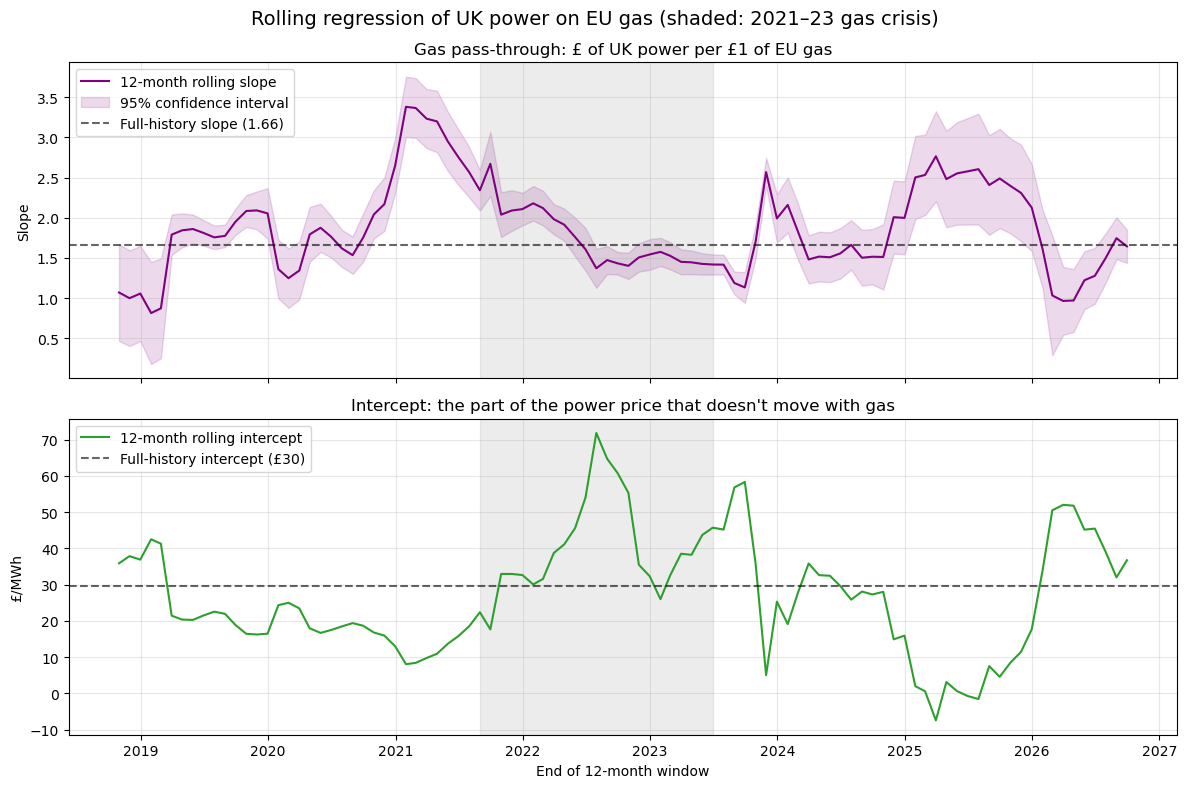

In [10]:
# Fit power = a + b × gas on each trailing 12-month window, stepping forward one month at a time.
# Carbon barely changes within 12 months, so each window's intercept absorbs it and the slope stays clean.
rolling_fits = []
for end in pd.date_range(uk_ttf.index[0] + pd.DateOffset(years=1), uk_ttf.index[-1], freq="ME"):
    window = uk_ttf.loc[end - pd.DateOffset(years=1) : end]
    fit = stats.linregress(window["EU Gas (£/MWh)"], window["UK Power"])
    rolling_fits.append({"date": end, "slope": fit.slope, "ci": 1.96 * fit.stderr, "intercept": fit.intercept})
rolling_fits = pd.DataFrame(rolling_fits).set_index("date")
full_fit = stats.linregress(uk_ttf["EU Gas (£/MWh)"], uk_ttf["UK Power"])

print("12-month slope at each September (£ of power per £1 of gas, ± 95% CI):")
september = rolling_fits[rolling_fits.index.month == 9]
print((september["slope"].round(2).astype(str) + " ± " + september["ci"].round(2).astype(str)).to_string())
print(f"Latest window (to {rolling_fits.index[-1].date()}): {rolling_fits['slope'].iloc[-1]:.2f} ± {rolling_fits['ci'].iloc[-1]:.2f}")
print(f"Full-history slope: {full_fit.slope:.2f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.plot(rolling_fits.index, rolling_fits["slope"], color="purple", linewidth=1.5, label="12-month rolling slope")
ax1.fill_between(rolling_fits.index, rolling_fits["slope"] - rolling_fits["ci"], rolling_fits["slope"] + rolling_fits["ci"],
                 color="purple", alpha=0.15, label="95% confidence interval")
ax1.axhline(full_fit.slope, color="black", linestyle="--", alpha=0.6, label=f"Full-history slope ({full_fit.slope:.2f})")
ax1.set_title("Gas pass-through: £ of UK power per £1 of EU gas", fontsize=12)
ax1.set_ylabel("Slope")

ax2.plot(rolling_fits.index, rolling_fits["intercept"], color="tab:green", linewidth=1.5, label="12-month rolling intercept")
ax2.axhline(full_fit.intercept, color="black", linestyle="--", alpha=0.6, label=f"Full-history intercept (£{full_fit.intercept:.0f})")
ax2.set_title("Intercept: the part of the power price that doesn't move with gas", fontsize=12)
ax2.set_ylabel("£/MWh")
ax2.set_xlabel("End of 12-month window")

for ax in (ax1, ax2):
    ax.axvspan(pd.Timestamp("2021-09-01"), pd.Timestamp("2023-06-30"), color="grey", alpha=0.15)
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)
fig.suptitle("Rolling regression of UK power on EU gas (shaded: 2021–23 gas crisis)", fontsize=14)
plt.tight_layout()
plt.show()

### What the rolling slope shows

- **No sustained downward trend.** The slope mostly sits between 1.4 and 2.1. The latest 12 months give **1.64 ± 0.21**, in line with the 2017–2026 average of 1.66.
- **Slope and intercept mirror each other.** When the slope jumps, the intercept falls (2021, 2025), and the reverse (2023, early 2026).
  In windows where gas barely moves, the regression can't separate "gas effect" from "fixed part", so it trades one for the other and the confidence band widens.
- **The dip to about 1.0 in early 2026 is not decoupling.** Those windows cover spring 2025 to spring 2026, when gas hardly moved (60-day sd below £2/MWh, see the correlation section), so the slope was poorly measured.
  Once the March 2026 gas shock entered the window, the slope returned to about 1.6.
- **2021–23 (shaded)** was the gas crisis: extreme prices, falling demand and government interventions distorted the relationship.
- **Rough link to how often gas sets the price:** if gas set the price every half-hour, the slope would equal the heat rate (about 1.9). 1.64 / 1.9 ≈ 0.86 suggests gas set the price roughly 85% of the time. This is an approximation that depends on the 1.9 assumption; test 2 estimates it a different way.

## Decoupling test 2: how often did gas NOT set the price?

The daily average mixes half-hours priced by gas plants with windy or low-demand half-hours priced by wind, nuclear or imports.
This test uses the **half-hourly** Elexon prices directly.

A gas plant's (CCGT's) cost to make 1 MWh of power is:

**cost = heat rate × (gas price + 0.184 tCO₂/MWh × (UK ETS price + £18 Carbon Price Support))**

A half-hour priced below 70% of that cost is counted as **not set by gas**: something cheaper was setting the price.
If the UK were becoming less dependent on gas, this share would rise year after year.

**Definitions and assumptions**
- **Gas price:** Dutch TTF front-month futures (`TTF=F`) daily close, converted from €/MWh to £/MWh with EURGBP.
  Weekends and holidays take the previous trading day's price, and each day's price applies to all 48 half-hours of that day.
  TTF stands in for the UK's own gas price (NBP), which isn't free on yfinance; the two usually trade close together.
- **Heat rate 1.9:** a gas plant (CCGT) at about 53% efficiency burns 1.9 MWh of gas per MWh of power.
- **0.184 tCO₂ per MWh of gas** burned, so about 0.35 tCO₂ per MWh of power (1.9 × 0.184).
- **"At or near gas cost"** means a half-hour priced at **70% or more** of the gas-plant cost. This has no upper limit, so it
  also includes half-hours priced *above* gas cost (scarcity spikes, expensive imports). "Below gas cost" means under 70%.
  The 70% gives room for plants running slightly more efficiently than assumed, cheaper gas contracts and bidding below cost.
- **Worked example (October 2026):** gas £67.5/MWh, carbon £49.41 + £18 = £67.4/t.
  Cost = 1.9 × (67.5 + 0.184 × 67.4) = 1.9 × (67.5 + 12.4) ≈ **£152/MWh**, so a half-hour counts as "at or near gas cost"
  if it is priced at **£106/MWh or more** (70% × £152).

- **Carbon prices:** annual UK ETS averages from the UK ETS Authority's official determinations (gov.uk). 2026 has no official figure yet, so £49 (the 2025 value) is used, with £62 (the late-September 2026 traded price) as a sensitivity check.
- **Period:** 2021 onwards only, because the UK ETS started in 2021 and a free daily EU carbon price for earlier years isn't available.
- **Fair comparison:** each year uses only 1 January to the last date of 2026 data, so the seasons match.

Half-hours from 1 Jan to 27 Oct of each year:
      Share below gas cost (%)  2026 at £62 carbon (%)  Avg power (£/MWh)  Avg gas-plant cost (£/MWh)
date                                                                                                 
2021                       6.1                     6.1               95.9                        83.6
2022                      36.7                    36.7              201.2                       254.5
2023                      12.4                    12.4               96.6                        97.7
2024                      17.5                    17.5               67.1                        73.3
2025                      16.5                    16.5               81.0                        84.6
2026                      14.5                    15.3              106.2                       110.1


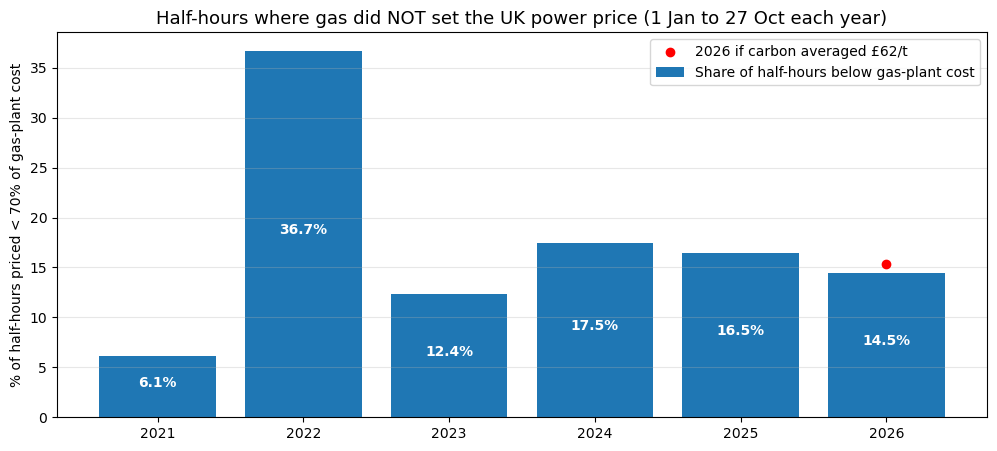

In [11]:
# Gas-plant (CCGT) cost of making 1 MWh of power = heat rate × (gas price + emissions × carbon price)
HEAT_RATE = 1.9    # MWh of gas burned per MWh of power (a CCGT about 53% efficient)
EMISSIONS = 0.184  # tCO2 per MWh of gas burned
CPS = 18.0         # £/tCO2 Carbon Price Support, paid by GB generators on top of the UK ETS
THRESHOLD = 0.7    # a half-hour priced below 70% of gas-plant cost is treated as "not set by gas"

# UK ETS annual average (£/tCO2) from the UK ETS Authority's official determinations on gov.uk:
# each is the average price over the 12 months to 11 November of that year.
# 2026 has no official figure yet, so it reuses 2025; UKAs traded around £62 in late September 2026 (tested below).
UK_ETS = {2021: 47.96, 2022: 83.03, 2023: 64.90, 2024: 41.84, 2025: 49.41, 2026: 49.41}

# Daily gas price for every calendar day (weekends take Friday's price), mapped onto each half-hour
gas_daily = uk_ttf["EU Gas (£/MWh)"].asfreq("D").ffill()
hh = mid[mid["date"].dt.year.isin(UK_ETS.keys())].copy()
hh["gas"] = hh["date"].map(gas_daily)
hh = hh.dropna(subset=["gas"])

# Compare the same part of every year (1 Jan to the last date of 2026 data), so seasons match
last_day = hh["date"].max()
hh = hh[hh["date"].dt.dayofyear <= last_day.dayofyear]


def share_below_gas_cost(df, uk_ets):
    """Share (%) of half-hours priced below THRESHOLD × gas-plant cost, by year."""
    carbon = df["date"].dt.year.map(uk_ets) + CPS
    cost = HEAT_RATE * (df["gas"] + EMISSIONS * carbon)
    return (df["price"] < THRESHOLD * cost).groupby(df["date"].dt.year).mean() * 100


shares = pd.DataFrame({
    "Share below gas cost (%)": share_below_gas_cost(hh, UK_ETS),
    "2026 at £62 carbon (%)": share_below_gas_cost(hh, {**UK_ETS, 2026: 62.0}),
})
check = hh.assign(cost=HEAT_RATE * (hh["gas"] + EMISSIONS * (hh["date"].dt.year.map(UK_ETS) + CPS)))
shares["Avg power (£/MWh)"] = check.groupby(check["date"].dt.year)["price"].mean()
shares["Avg gas-plant cost (£/MWh)"] = check.groupby(check["date"].dt.year)["cost"].mean()
print(f"Half-hours from 1 Jan to {last_day:%d %b} of each year:")
print(shares.round(1).to_string())

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(shares.index, shares["Share below gas cost (%)"], color="tab:blue", label="Share of half-hours below gas-plant cost")
ax.scatter([2026], [shares.loc[2026, "2026 at £62 carbon (%)"]], color="red", zorder=3, label="2026 if carbon averaged £62/t")
for year, value in shares["Share below gas cost (%)"].items():
    ax.text(year, value / 2, f"{value:.1f}%", ha="center", color="white", fontweight="bold")
ax.set_title(f"Half-hours where gas did NOT set the UK power price (1 Jan to {last_day:%d %b} each year)", fontsize=13)
ax.set_ylabel(f"% of half-hours priced < {THRESHOLD:.0%} of gas-plant cost")
ax.legend(loc="upper right")
ax.grid(True, axis="y", alpha=0.3)
plt.show()

12-month rolling share of half-hours priced at or near gas cost (%), each December and latest:
date
2021-12-01    93.1
2022-12-01    60.8
2023-12-01    84.8
2024-12-01    82.8
2025-12-01    84.6
Latest (Oct 2026): 86.4%

Average share by calendar month, 2023 onwards (%):
date
1     90.5
2     91.0
3     86.2
4     80.5
5     89.2
6     82.2
7     87.0
8     80.6
9     81.5
10    78.4
11    87.7
12    76.6


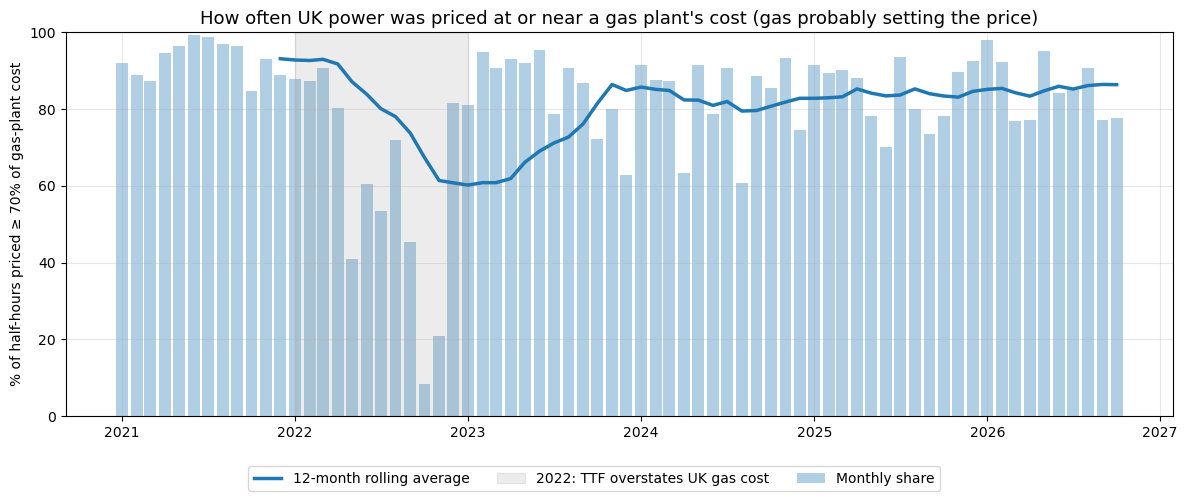

In [12]:
# Same test month by month, using every half-hour since 2021 (not just Jan to Oct)
hh_all = mid[mid["date"].dt.year.isin(UK_ETS.keys())].copy()
hh_all["gas"] = hh_all["date"].map(gas_daily)
hh_all = hh_all.dropna(subset=["gas"])
carbon = hh_all["date"].dt.year.map(UK_ETS) + CPS
gas_cost = HEAT_RATE * (hh_all["gas"] + EMISSIONS * carbon)
hh_all["near_gas_cost"] = hh_all["price"] >= THRESHOLD * gas_cost

monthly_share = hh_all.groupby(hh_all["date"].dt.to_period("M"))["near_gas_cost"].mean() * 100
monthly_share.index = monthly_share.index.to_timestamp()
rolling_share = monthly_share.rolling(12).mean()

print("12-month rolling share of half-hours priced at or near gas cost (%), each December and latest:")
print(rolling_share[rolling_share.index.month == 12].round(1).to_string())
print(f"Latest ({rolling_share.index[-1]:%b %Y}): {rolling_share.iloc[-1]:.1f}%")

# Seasonality: average share by calendar month, 2023 onwards (2022 is distorted by the TTF/NBP gap)
recent = monthly_share[monthly_share.index.year >= 2023]
print("\nAverage share by calendar month, 2023 onwards (%):")
print(recent.groupby(recent.index.month).mean().round(1).to_string())

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(monthly_share.index, monthly_share, width=25, color="tab:blue", alpha=0.35, label="Monthly share")
ax.plot(rolling_share.index, rolling_share, color="tab:blue", linewidth=2.5, label="12-month rolling average")
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color="grey", alpha=0.15,
           label="2022: TTF overstates UK gas cost")
ax.set_ylim(0, 100)
ax.set_title("How often UK power was priced at or near a gas plant's cost (gas probably setting the price)", fontsize=13)
ax.set_ylabel(f"% of half-hours priced ≥ {THRESHOLD:.0%} of gas-plant cost")
fig.legend(loc="lower center", ncol=3)
ax.grid(True, alpha=0.3)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

### What the half-hourly test shows 
#### This basically show when gas definitely does not set the price

- **The cost model is realistic.** From 2023 to 2026, the average estimated gas-plant cost is within about £3–6/MWh of the actual average power price.
- **Gas did not set the price less often.** The share of half-hours below gas cost went from 17.5% (2024) to 16.5% (2025) to **14.5%** (2026), or 15.3% if carbon averaged £62.
  The fall holds at every threshold from 50% to 80% of cost, so it doesn't depend on the 70% choice.
- **2022 is an outlier, not a trend.** TTF overstates the UK's gas cost that year: the UK's own gas price (NBP) traded well below TTF in 2022 as LNG flooded into Britain and export capacity to Europe was full. The cost estimate is too high, so too many half-hours look "below cost".
- **About 86% of half-hours in 2026 were priced at or near a gas plant's cost**, and only about 14.5% clearly below it, so gas set the price in most half-hours.
  This 86% is an upper estimate of how often gas set the price: it also includes half-hours where something *more* expensive than gas set it (scarcity spikes, pricey imports).
- **The monthly chart shows a modest rise since 2024.** The 12-month rolling share went from about 83% (end of 2024) to 85% (end of 2025) to **86%** (October 2026).
  This is a recovery rather than a new high: 2021 was about 93%. The 2022 dip reflects the TTF/NBP gap, not a real change.
- **Seasonal pattern.** Averaged over 2023 to October 2026 (2022 left out because of the TTF/NBP gap), gas sets the price most in
  **January and February (about 91%)**. The lowest months are **December (77%)**, October (78%), April (81%) and August (81%).
  December being lowest is surprising for a winter month: it is likely the Christmas demand drop plus windy weather, but with only
  three Decembers in the average, treat it as tentative. For hedging, January and February are when power is most tied to gas.
- **Consistent with the rolling slope.** 1.64 / 1.9 ≈ 0.86 points the same way, but both estimates rely on the same 1.9 heat-rate assumption, so treat them as consistent, not as independent proof.

**Caveats:** the 70% threshold is a judgement call; carbon is an annual average; TTF is a proxy for the UK gas price (NBP would be more exact); 2026 is year-to-date.

### Is the 70% cutoff driving the result?

The 70% cutoff is a judgement call, so this checks it two ways:
1. **Where do prices actually sit relative to gas cost?** If gas sets most prices, the ratio power price ÷ gas-plant cost should cluster around 1.0.
2. **Sensitivity:** recompute the share at cutoffs from 50% to 90% and check whether the 2024 → 2026 trend changes direction.


Median ratio since 2023: 1.01; 75% of half-hours sit between 0.75 and 1.35

Share of half-hours at or near gas cost (%) by cutoff:
            Last 12 months  YTD 2023  YTD 2024  YTD 2025  YTD 2026
50% cutoff            90.5      92.4      88.4      87.4      89.8
60% cutoff            88.7      90.7      85.9      85.6      87.9
70% cutoff            86.3      87.6      82.5      83.5      85.5
80% cutoff            82.3      80.7      77.3      79.9      81.5
90% cutoff            74.3      67.2      64.8      70.7      73.3


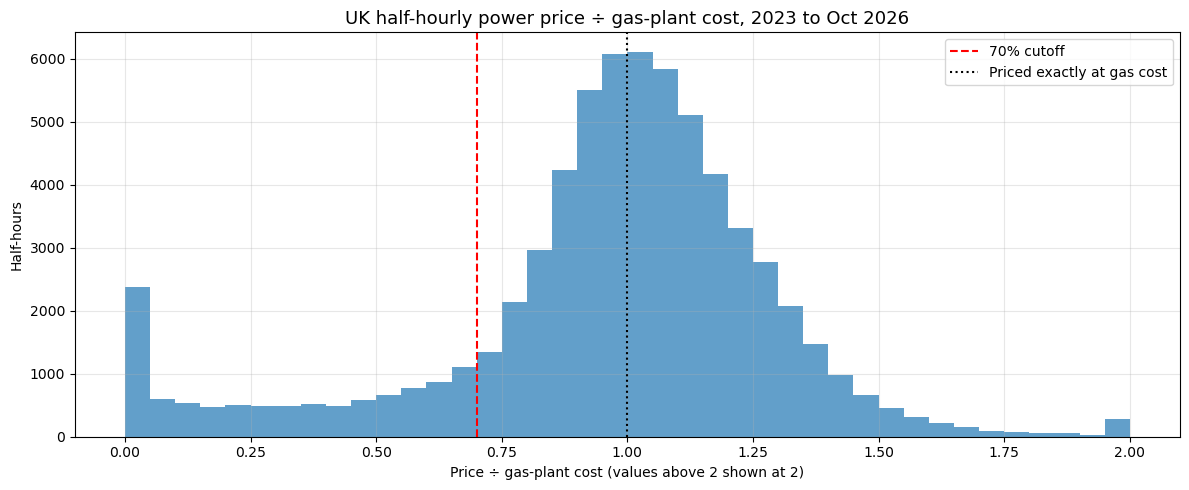

In [13]:
# Ratio of each half-hour's price to the gas-plant cost (1.0 = priced exactly at gas cost)
hh_all["ratio"] = hh_all["price"] / gas_cost
since_2023 = hh_all[hh_all["date"].dt.year >= 2023]
last_12m = hh_all[hh_all["date"] > hh_all["date"].max() - pd.DateOffset(years=1)]

in_cluster = since_2023["ratio"].between(0.75, 1.35).mean() * 100
print(f"Median ratio since 2023: {since_2023['ratio'].median():.2f}; {in_cluster:.0f}% of half-hours sit between 0.75 and 1.35")

# Sensitivity: share at or near gas cost for each cutoff, last 12 months and year-to-date by year
ytd = hh_all[hh_all["date"].dt.dayofyear <= hh_all["date"].max().dayofyear]
sensitivity = pd.DataFrame({
    f"{t:.0%} cutoff": {
        "Last 12 months": (last_12m["ratio"] >= t).mean() * 100,
        **((ytd["ratio"] >= t).groupby(ytd["date"].dt.year).mean().loc[2023:] * 100).rename(lambda y: f"YTD {y}").to_dict(),
    }
    for t in [0.5, 0.6, 0.7, 0.8, 0.9]
}).T
print("\nShare of half-hours at or near gas cost (%) by cutoff:")
print(sensitivity.round(1).to_string())

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(since_2023["ratio"].clip(0, 2), bins=np.arange(0, 2.05, 0.05), color="tab:blue", alpha=0.7)
ax.axvline(THRESHOLD, color="red", linestyle="--", label=f"{THRESHOLD:.0%} cutoff")
ax.axvline(1.0, color="black", linestyle=":", label="Priced exactly at gas cost")
ax.set_title("UK half-hourly power price ÷ gas-plant cost, 2023 to Oct 2026", fontsize=13)
ax.set_xlabel("Price ÷ gas-plant cost (values above 2 shown at 2)")
ax.set_ylabel("Half-hours")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### What the cutoff check shows

- **Prices cluster around gas cost.** The median half-hour is priced at about 1.0 × gas-plant cost, and roughly three-quarters sit
  between 0.75 and 1.35. That cluster is gas plants setting the price.
- **Below about 0.7 there is no cluster:** a thin, flat spread down to zero plus a spike near zero (windy periods and negative prices).
  So 70% sits where the gas cluster ends, which is why it was chosen. It also leaves room for plants more efficient than the 1.9
  heat rate assumed, cheaper gas contracts and the gap between TTF and the UK's NBP gas price.
- **The headline level depends on the cutoff; the conclusion doesn't.** Over the last 12 months the share is about 90% at a 50%
  cutoff, 86% at 70% and 74% at 90%. But at every cutoff the share is higher in 2026 than in 2024, so "not decoupling" holds.
- **How to report it:** "about 82–89% of half-hours (60–80% cutoffs)", with 86% as the central estimate.


## Conclusion

**UK power has not become less dependent on gas.**

- **Correlation** between UK power and TTF rose and fell over the past two years, but this mostly reflects how much gas prices moved
  (r = 0.82 between rolling correlation and gas volatility), not a change in dependence.
- **Regression:** UK power rises by about £1.6–1.7/MWh for each £1/MWh rise in gas, matching a gas power station's fuel use. The latest 12-month slope (1.64 ± 0.21) is in line with the 2017–2026 average (1.66), with no sustained downward trend.
- **Out-of-sample residual:** a gas-only model fitted before August 2026 predicted the August–October rise in power within its normal error.
- **Half-hourly test:** about 86% of half-hours in 2026 were priced at or near a gas plant's cost. The 12-month rolling share has risen modestly since 2024 (about 83% → 86%), though it remains below 2021 (93%). Gas is setting the UK price slightly *more* often, not less.
- **TTF rising faster than power in percentage terms is expected:** about £30/MWh of the power price, mostly carbon cost, does not move with gas.

**Limitations:** TTF is a proxy for the UK gas price (NBP); carbon prices are annual averages; wind output and demand are not modelled.
The residual test covers only August to late October, so re-run all three tests after winter 2026–27, when gas usually sets the price most often.